In [185]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer

from scipy import stats


# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [186]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [187]:
# Handling object datatype
print(dataset.select_dtypes(object)) # ID Column

print("Before: "+str(dataset.select_dtypes(object).shape))

dataset = dataset.drop("ID",axis=1)
print("After: "+str(dataset.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)


In [188]:
print(dataset.select_dtypes(np.int64))

print("Before: "+str(dataset.select_dtypes(np.int64).shape))

dataset['original_shape_VoxelVolume'] = dataset['original_shape_VoxelVolume'].astype(np.float64)
print("After: "+str(dataset.select_dtypes(np.int64).shape))

# Save column names of categorical features for later
categorical_names = dataset.select_dtypes(np.int64).columns
categorical_names

     pCR (outcome)  ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  \
0                1   0    0     0                1           3              3   
1                0   1    1     0                0           3              3   
2                1   0    0     0                1           2              1   
3                0   0    0     0                1           3              3   
4                0   1    0     0                0           2              1   
..             ...  ..  ...   ...              ...         ...            ...   
395              0   1    0     1                0           3              2   
396              0   0    0     0                1           3              3   
397              0   0    0     0                1           2              1   
398              0   1    0     0                0           3              3   
399              0   1    0     0                0           2              1   

     HistologyType  LNStatu

Index(['pCR (outcome)', 'ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade',
       'Proliferation', 'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

### Handling float64 datatype
#### Continuous Features

Nothing specific left, data is all continuous

In [189]:
# Save column names of continuous features for later
dataset.select_dtypes(np.float64)
continuous_names = dataset.select_dtypes(np.float64).columns
continuous_names

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=109)

## General Preprocessing
1. Null handling (converting '999')
2. Outlier handling
3. Data Imputation
4. Balancing data (Frequency handling)
5. Data Normalisation

### 1. Null Handling
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [190]:
# Replace 999 (placeholder) with actual null values
dataset = dataset.replace([999],np.nan)

# Viewing features with null values
non_null = dataset.isnull().sum()
non_null = non_null[non_null > 0]
non_null

pCR (outcome)       5
PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

### 2. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor
5. DBSCAN(?)

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

<Axes: >

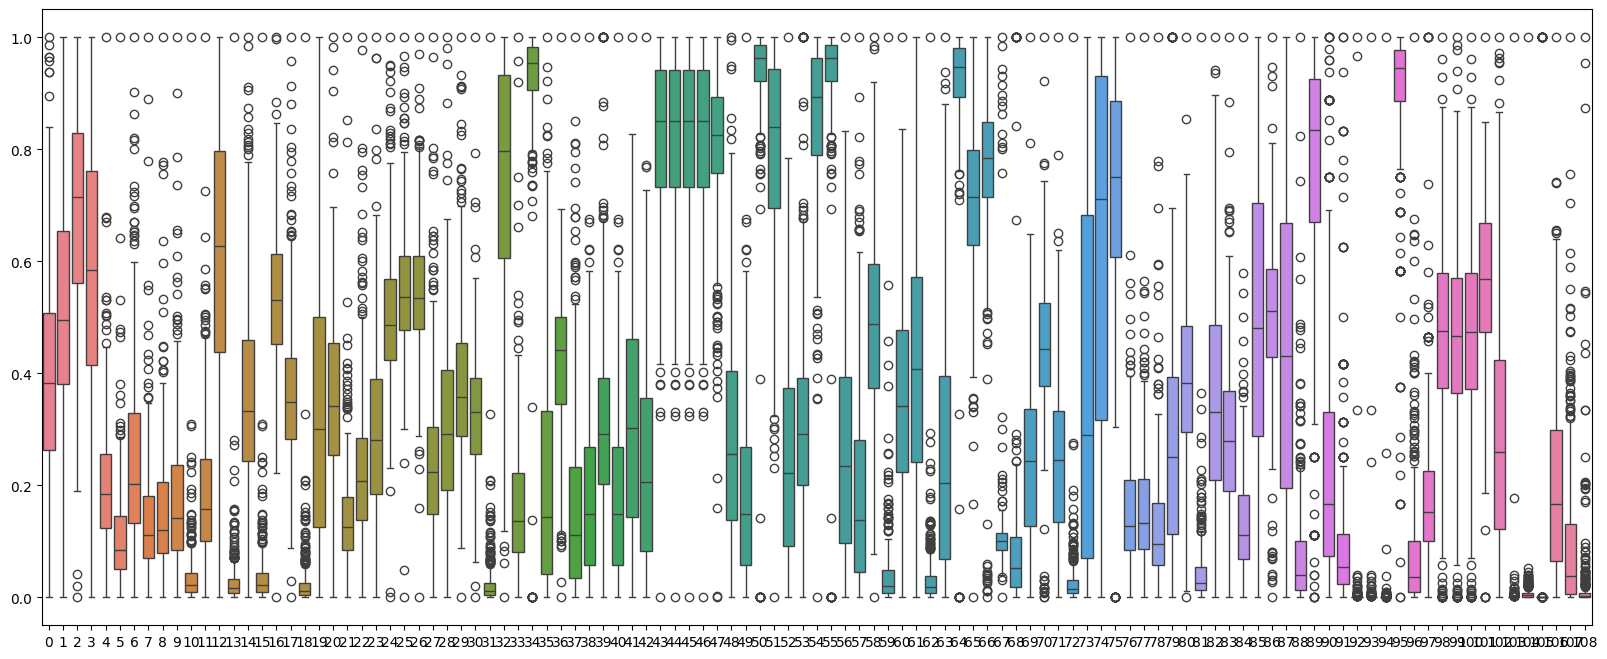

In [191]:
# Data visualisation
scaler = MinMaxScaler()

# Boxplot below shows normalised continuous features + outliers
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(dataset[continuous_names]),ax=ax)

Note: Above boxplot, categorical features normalised to 0-1 range, shows prevalence of outliers. Handling using naive methods, such as Z-score or IQR, may be ineffective

##### Option 1 - Z-score

In [192]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(dataset))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))
for index in outlier_indices:
    print(index)

Outlier total: 576
(np.int64(0), np.int64(1))
(np.int64(1), np.int64(1))
(np.int64(6), np.int64(1))
(np.int64(8), np.int64(1))
(np.int64(9), np.int64(1))
(np.int64(32), np.int64(100))
(np.int64(32), np.int64(101))
(np.int64(32), np.int64(102))
(np.int64(32), np.int64(106))
(np.int64(34), np.int64(102))
(np.int64(34), np.int64(106))
(np.int64(34), np.int64(119))
(np.int64(37), np.int64(100))
(np.int64(37), np.int64(101))
(np.int64(37), np.int64(102))
(np.int64(37), np.int64(106))
(np.int64(54), np.int64(45))
(np.int64(54), np.int64(50))
(np.int64(54), np.int64(61))
(np.int64(54), np.int64(64))
(np.int64(54), np.int64(66))
(np.int64(54), np.int64(75))
(np.int64(54), np.int64(77))
(np.int64(54), np.int64(78))
(np.int64(54), np.int64(79))
(np.int64(54), np.int64(81))
(np.int64(54), np.int64(86))
(np.int64(54), np.int64(90))
(np.int64(54), np.int64(108))
(np.int64(54), np.int64(112))
(np.int64(54), np.int64(116))
(np.int64(57), np.int64(48))
(np.int64(57), np.int64(68))
(np.int64(59), np.in

In [193]:
# Applying z-score

dataset[(np.abs(stats.zscore(dataset)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Z-score is clearly ineffective. Implication from above cell is that outliers are prevalent in all samples, hence they are all removed

##### Option 2 - Interquartile Range

In [194]:
# Calculating Interquartile Range
Q1 = dataset.quantile(0.25)
Q3 = dataset.quantile(0.75)
IQR = Q3 - Q1

In [195]:
# Outputting number of outliers per column
outliers_iqr = ((dataset < (Q1 - 1.5 * IQR)) | (dataset > (Q3 + 1.5 * IQR)))

print("Number of outliers per column:")
outliers_col = outliers_iqr.sum()
outliers_col = outliers_col[outliers_col > 0]

print(outliers_col)

Number of outliers per column:
pCR (outcome)                     84
RelapseFreeSurvival (outcome)      8
HistologyType                     59
original_shape_Elongation          3
original_shape_LeastAxisLength    13
                                  ..
original_ngtdm_Busyness           35
original_ngtdm_Coarseness         61
original_ngtdm_Complexity          6
original_ngtdm_Contrast           36
original_ngtdm_Strength           59
Length: 102, dtype: int64


In [196]:
# Applying IQR (incomplete)
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

upper_arr = np.where(dataset >= upper)[0]
lower_arr = np.where(dataset <= lower)[0]

# dataset.drop(index=upper_arr, inplace=True)
# dataset.drop(index=lower_arr, inplace=True)

##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

IsoForest_Outlier
 1    380
-1     20
Name: count, dtype: int64


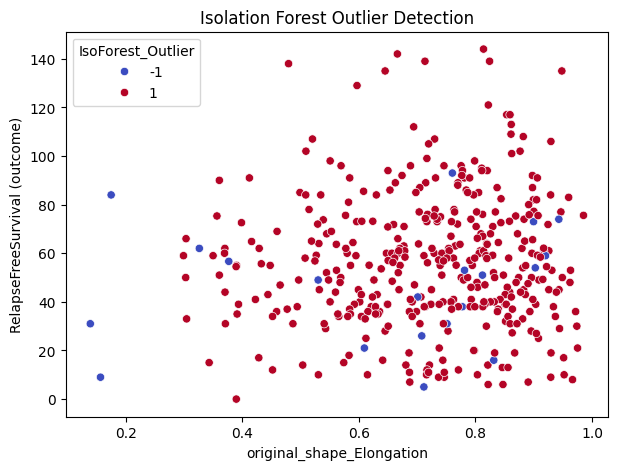

In [198]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
y_pred_iso = iso.fit_predict(dataset)

dataset["IsoForest_Outlier"] = y_pred_iso
print(dataset["IsoForest_Outlier"].value_counts())

plt.figure(figsize=(7, 5))
sns.scatterplot(x="original_shape_Elongation", y="RelapseFreeSurvival (outcome)", data=dataset,
                hue="IsoForest_Outlier", palette="coolwarm")
plt.title("Isolation Forest Outlier Detection")
plt.show()

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],

### 3. Data Imputation
Performed after outlier handling as imputation should perform better with clean(er) data, especially for null values

Null values can be removed or imputed, or a combination of both consider only removing Gene null values, as other null totals are [minimal](#1-null-handling)  
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect algorithms

##### 1. Removal of all null values
Majority of null values are from one feature ('Gene'). Is it worth removing them all?

In [199]:
# # Removal (entirely)
# dataset = dataset.dropna()

##### 2. Partial Removal, Partial Imputation
1. Removing Gene
2. Imputing other features (format: x|y -> continuous|categorical)

    2.1 Mean|Mode Imputation
    
    2.2 Mode|Mode Imputation

Impute continuous features using the mean and categorical features using the mode

Removes the majority of outliers ('Gene'), imputes the rest.

In [200]:
imputer_mean = SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')

In [201]:
## 1. Removing Gene
dataset['Gene'].dropna()

## 2. Imputing other features (format: x|y -> continuous|categorical)
    
### 2.1 Mean|Mode
dataset[continuous_names] = imputer_mean.fit_transform(dataset[continuous_names])
dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])

# ### 2.2 Mode|Mode
# dataset[continuous_names] = imputer_mode.fit_transform(dataset[continuous_names])
# dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])


# Outputting null values: none remaining
non_null = dataset.isnull().sum()
non_null = non_null[non_null > 0]
non_null

Series([], dtype: int64)

##### 3. Imputation of all null values
Added this case for comparison

In [202]:
# dataset[continuous_names] = imputer_mean.fit_transform(dataset[continuous_names])
# dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])

##### IterativeImputer

1. Nearest neighbour imputation (different scales in features may be punishing)

Allows for models to determine imputation

[This](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation:~:text=of%20IterativeImputer.-,7.4.3.2.%20Multiple%20vs.%20Single%20Imputation,-%23) might be helpful

### 4. Balancing
We can use stratification when building models to make sure the data is split in the same way as the distribution. We should, therefore, clean up the distribution of data
- Applies for classification as we split based on discrete outcome
- Question: How do we apply to regression?

1. Classification (pCR (outcome))
2. Regression (RelapseFreeSurvival (outcome))

##### 1. Classification (pCR (outcome))
Use a histogram to view relative frequencies

pCR (outcome)
0.0    316
1.0     84
Name: count, dtype: int64


<Axes: xlabel='pCR (outcome)', ylabel='count'>

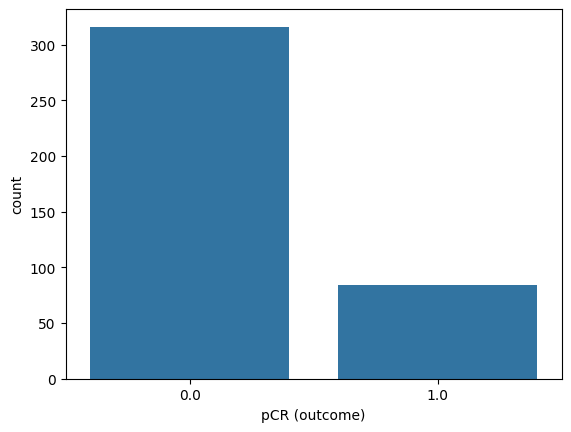

In [203]:
# pCR (outcome) visualisation
print(dataset['pCR (outcome)'].value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.countplot(x="pCR (outcome)", data=dataset)

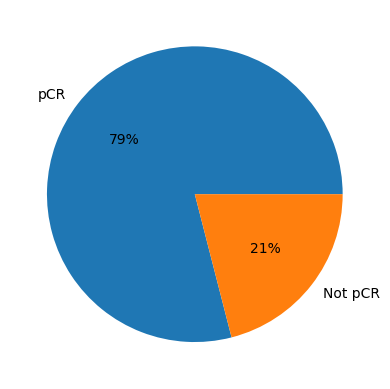

In [204]:
# Pie chart

plt.pie(dataset['pCR (outcome)'].value_counts(), labels=['pCR', 'Not pCR'], autopct='%.f%%')
plt.show()

In [205]:
# Balancing? Then see effect on distribution?

##### 2. Regression (RelapseFreeSurvival (outcome))

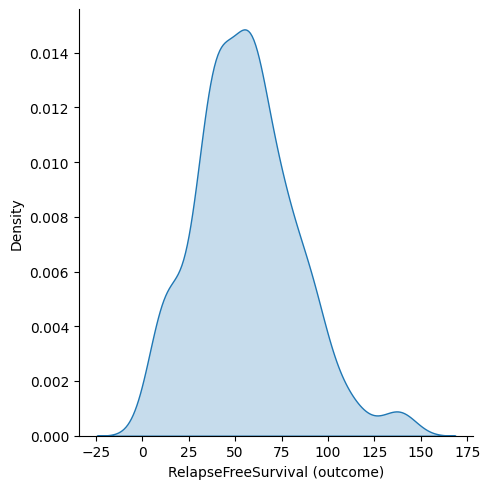

In [206]:
sns.displot(x="RelapseFreeSurvival (outcome)", data=dataset, kind="kde", fill=True)

In [207]:
# Balancing?

### 5. Normalisation
Options:
1. MinMax
2. Z-normalisation
3. Vector Normalisation
4. More research: https://www.geeksforgeeks.org/python/data-normalization-with-pandas/

##### 1. MinMax

<Axes: >

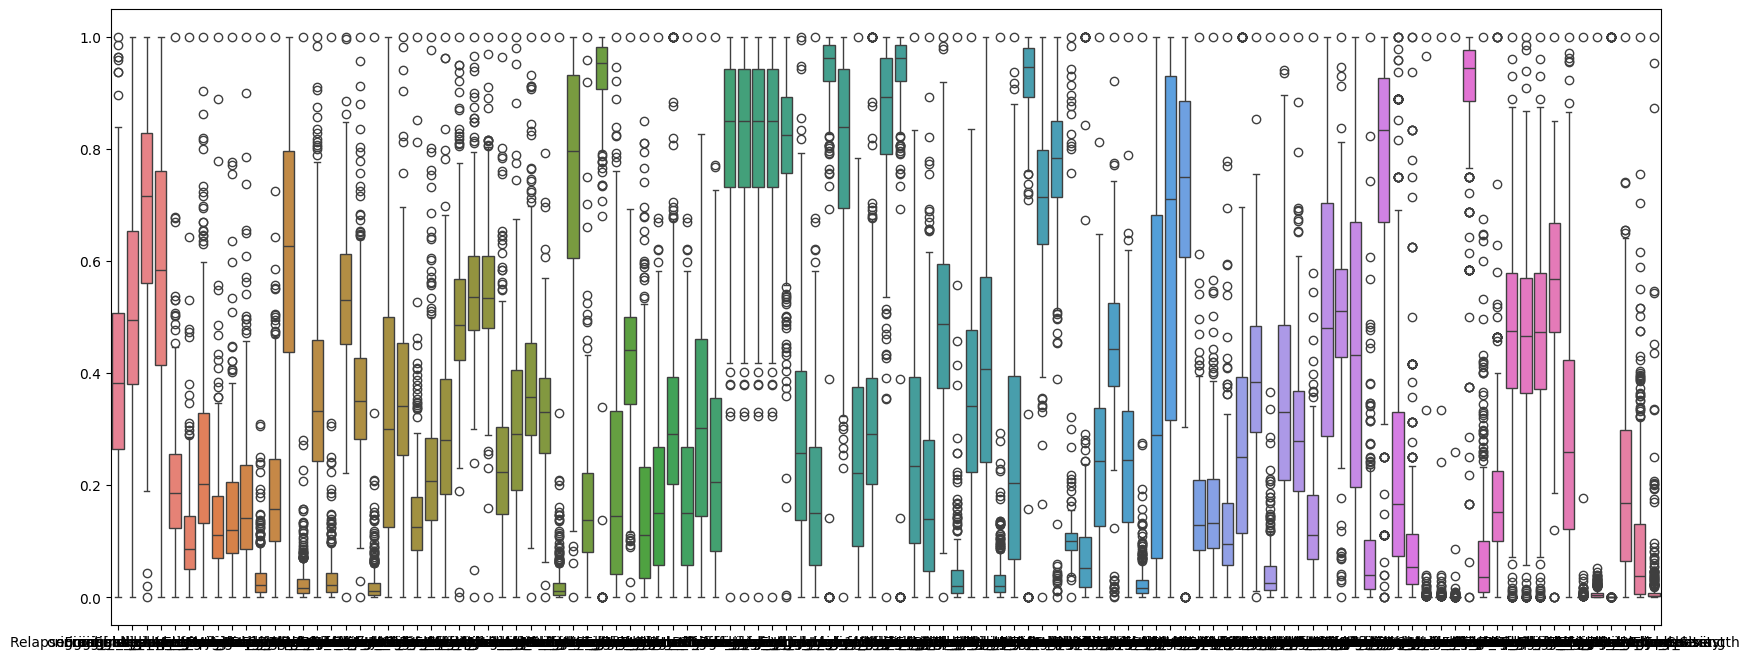

In [208]:
scaler = MinMaxScaler()
dataset[continuous_names] = scaler.fit_transform(dataset[continuous_names])
dataset[continuous_names]

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[continuous_names],ax=ax)

In [209]:
# %store dataset